In [31]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns



In [3]:
df=pd.read_csv('car_price_prediction_synthetic.csv')

In [5]:
df.corr(numeric_only=True)['selling_price']

year             0.515216
km_driven       -0.219740
engine_cc        0.689943
max_power_bhp    0.732840
owner_count     -0.114396
selling_price    1.000000
Name: selling_price, dtype: float64

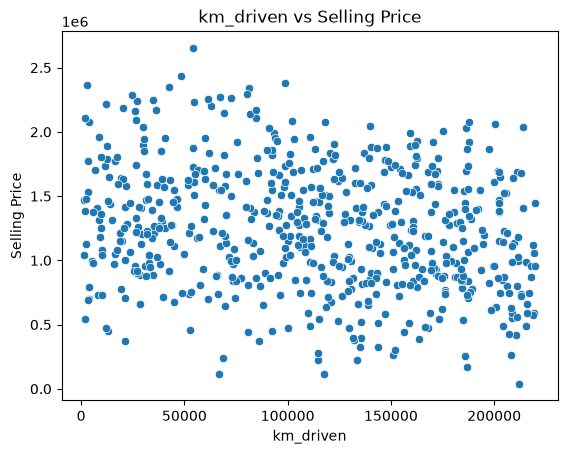

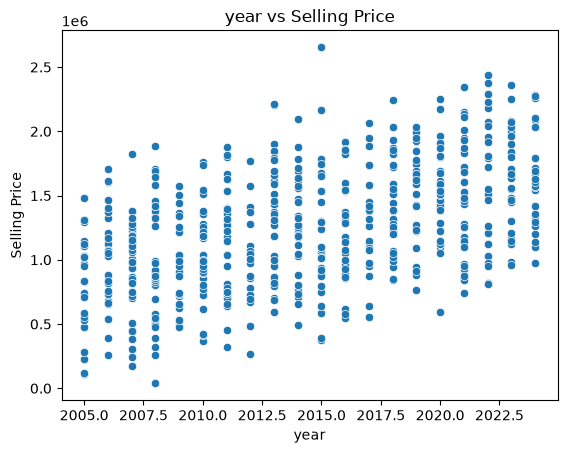

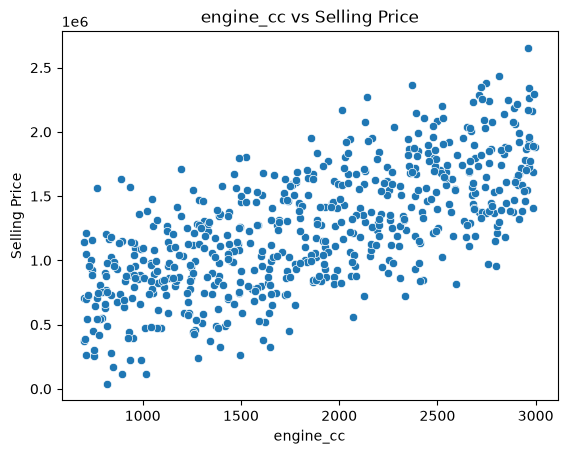

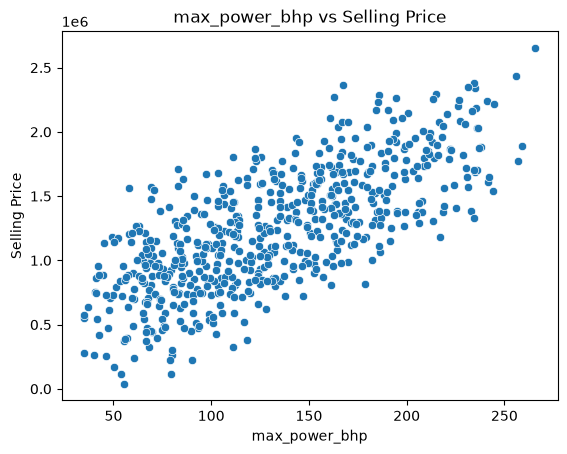

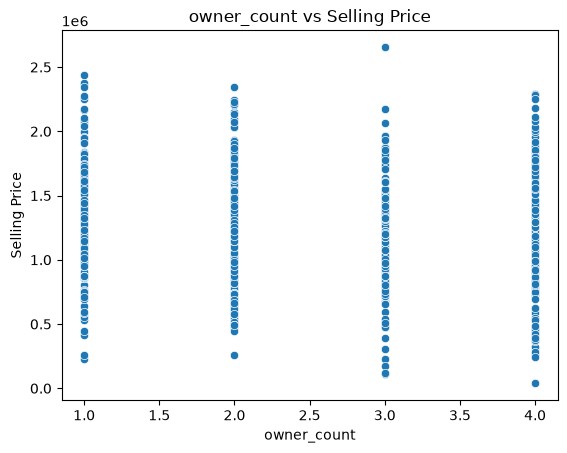

In [32]:
input_columns = ['km_driven', 'year', 'engine_cc', 'max_power_bhp','owner_count']

for col in input_columns:
    sns.scatterplot(x=df[col], y=df['selling_price'])
    plt.title(f'{col} vs Selling Price')
    plt.xlabel(col)
    plt.ylabel('Selling Price')
    plt.show()

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

In [7]:
X = df.drop(columns='selling_price')
Y = df['selling_price']

In [8]:
xtrain,xtest,ytrain,ytest=train_test_split(X,Y,train_size=0.8,random_state=42)

In [10]:
xtrain


,year,km_driven,engine_cc,max_power_bhp,owner_count
145,2022,80440,2994,215.2,4
9,2006,188737,2915,169.2,3
375,2006,50017,1432,95.9,2
523,2021,53985,2381,160.1,2
188,2009,120019,2749,195.3,2
...,...,...,...,...,...
71,2008,135356,951,57.0,4
106,2020,2223,1285,98.2,3
270,2010,100634,2764,189.1,2
435,2007,163521,1933,157.2,2


In [11]:
ytrain


145    2291351.0
9      1323902.0
375    1052943.0
523    1872559.0
188    1367444.0
         ...    
71      393793.0
106    1123565.0
270    1758948.0
435     867451.0
102    1264072.0
Name: selling_price, Length: 480, dtype: float64

In [12]:
model=LinearRegression()
model.fit(xtrain,ytrain)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](5,)","[ 42268.2 , -1.41, 161.12, 4574.08,-45420.94]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](5,)","['year','km_driven','engine_cc','max_power_bhp','owner_count']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-8.453e+07
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(5)


In [13]:
model.intercept_    # it is the base/initial value of y when x=0

np.float64(-84532814.42384836)

In [14]:
model.coef_         # it is slope ,also known as weights
                    #the rate of change of y w.r.t x by 1 unit

array([ 4.22681957e+04, -1.41170935e+00,  1.61120902e+02,  4.57408223e+03,
       -4.54209439e+04])

In [15]:
ytrain_predicted=model.predict(xtrain)

In [29]:
# r2 score
# Test score
from sklearn.metrics import r2_score
ytest_predicted=model.predict(xtest)
r2_test_score=r2_score(ytest,ytest_predicted)
r2_test_score

0.8627262315151849

In [25]:
ytest_predicted=model.predict(xtest)

In [26]:
from sklearn.metrics import mean_absolute_error
ytest_predicted=model.predict(xtest)
mae_test_score=mean_absolute_error(ytest,ytest_predicted)
mae_test_score

148163.8802222032

In [27]:
from sklearn.metrics import root_mean_squared_error
ytest_predicted=model.predict(xtest)
rmse_test_score=root_mean_squared_error(ytest,ytest_predicted)
rmse_test_score

186668.81832193266